# 01 — Exploratory data analysis: URBAN-SED (self-contained)

No `src` imports: the annotation parsing, frontend config and plotting code are
inline, so this notebook runs on Colab after the dataset is extracted under
`data/`.

Questions: split/class balance, event durations, polyphony, label density,
time-frequency examples, co-occurrence, annotation sanity, processed targets.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "URBAN-SED_v2.0.0"
PROCESSED = ROOT / "data" / "processed" / "urbansed"
SPLITS = ["train", "validate", "test"]
CLASSES = ["air_conditioner", "car_horn", "children_playing", "dog_bark",
           "drilling", "engine_idling", "gun_shot", "jackhammer", "siren",
           "street_music"]

SAMPLE_RATE = 16000
HOP_LENGTH = 320
NUM_FRAMES = 500
N_MELS = 64
FRAME_RATE = SAMPLE_RATE / HOP_LENGTH


def parse_annotation(path):
    events = []
    for line in Path(path).read_text().splitlines():
        parts = line.strip().split("\t")
        if len(parts) < 3:
            continue
        start, end, label = float(parts[0]), float(parts[1]), parts[2]
        events.append((CLASSES.index(label), start, end))
    return events


def discover_split(root, split):
    root = Path(root)
    rows = []
    for ann in sorted((root / "annotations" / split).glob("*.txt")):
        rows.append({
            "name": ann.stem,
            "audio": root / "audio" / split / f"{ann.stem}.wav",
            "events": parse_annotation(ann),
        })
    return rows


def logmel(path):
    y, _ = librosa.load(path, sr=SAMPLE_RATE, mono=True)
    mel = librosa.feature.melspectrogram(
        y=y, sr=SAMPLE_RATE, n_fft=1024, hop_length=HOP_LENGTH,
        win_length=400, n_mels=N_MELS, fmin=0, fmax=8000,
    )
    mel = librosa.power_to_db(mel, ref=1.0)
    mel = mel.T[:NUM_FRAMES]
    return y, mel


print("raw exists:", RAW.exists())
print("processed exists:", PROCESSED.exists())

raw exists: True
processed exists: True


## Split sizes and event counts

In [2]:
split_rows = {split: discover_split(RAW, split) for split in SPLITS}
for split, rows in split_rows.items():
    n_events = sum(len(r["events"]) for r in rows)
    print(f"{split:>8s}: {len(rows):5d} clips  {n_events:6d} events  "
          f"({n_events / len(rows):.2f} events/clip)")

   train:  6000 clips   29919 events  (4.99 events/clip)
validate:  2000 clips    9956 events  (4.98 events/clip)
    test:  2000 clips    9956 events  (4.98 events/clip)


## Class distribution and durations

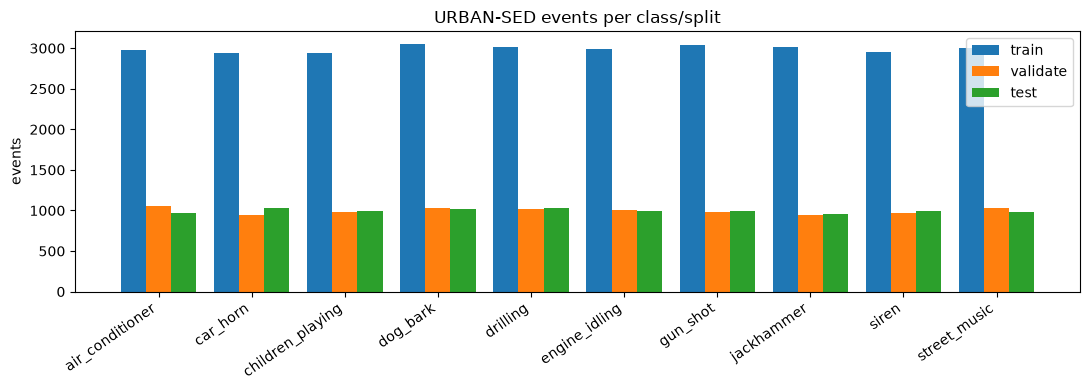

events: 49831  mean 2.01s  median 1.87s  p95 3.89s  max 4.79s


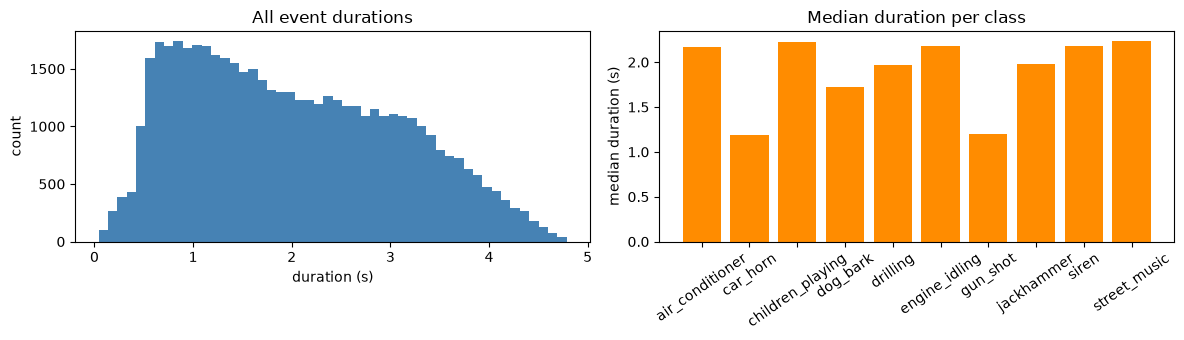

In [3]:
counts = np.zeros((len(SPLITS), len(CLASSES)), dtype=int)
durations = {i: [] for i in range(len(CLASSES))}
for si, split in enumerate(SPLITS):
    for row in split_rows[split]:
        for cid, start, end in row["events"]:
            counts[si, cid] += 1
            durations[cid].append(end - start)

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.27
x = np.arange(len(CLASSES))
for si, split in enumerate(SPLITS):
    ax.bar(x + (si - 1) * width, counts[si], width, label=split)
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=35, ha="right")
ax.set_ylabel("events"); ax.set_title("URBAN-SED events per class/split")
ax.legend(); plt.tight_layout(); plt.show()

all_d = np.concatenate([np.asarray(v) for v in durations.values() if v])
print(f"events: {all_d.size}  mean {all_d.mean():.2f}s  median {np.median(all_d):.2f}s  "
      f"p95 {np.percentile(all_d, 95):.2f}s  max {all_d.max():.2f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(all_d, bins=50, color="steelblue")
axes[0].set_xlabel("duration (s)"); axes[0].set_ylabel("count")
axes[0].set_title("All event durations")
axes[1].bar(CLASSES, [np.median(v) if v else 0 for v in durations.values()], color="darkorange")
axes[1].set_ylabel("median duration (s)"); axes[1].tick_params(axis="x", rotation=35)
axes[1].set_title("Median duration per class")
plt.tight_layout(); plt.show()

## Polyphony and label density

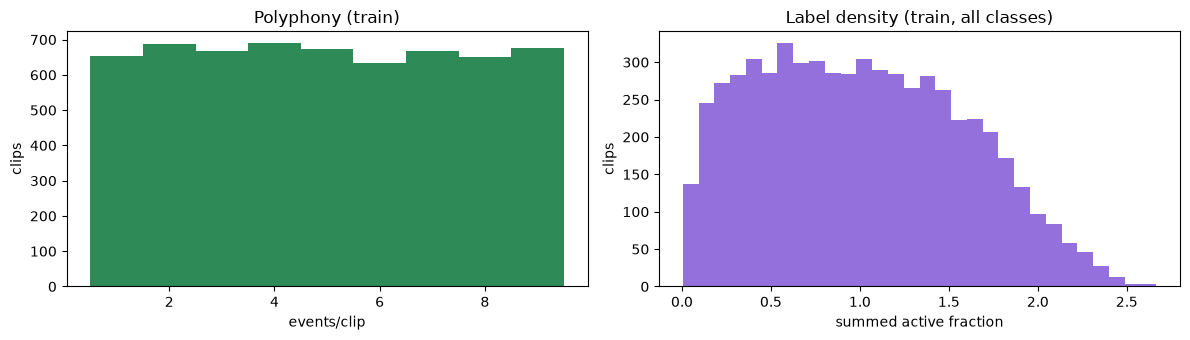

mean events/clip 4.99; mean active 1.005


In [4]:
events_per_clip = np.array([len(r["events"]) for r in split_rows["train"]])
active = np.array([sum(e - s for _, s, e in r["events"]) / 10.0 for r in split_rows["train"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(events_per_clip, bins=np.arange(0.5, events_per_clip.max() + 1.5, 1),
             color="seagreen")
axes[0].set_xlabel("events/clip"); axes[0].set_ylabel("clips")
axes[0].set_title("Polyphony (train)")
axes[1].hist(active, bins=30, color="mediumpurple")
axes[1].set_xlabel("summed active fraction"); axes[1].set_ylabel("clips")
axes[1].set_title("Label density (train, all classes)")
plt.tight_layout(); plt.show()
print(f"mean events/clip {events_per_clip.mean():.2f}; mean active {active.mean():.3f}")

## A clip in the time-frequency domain

/Users/minh.l/workspace/.researchs/event-proposal-networks-from-scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


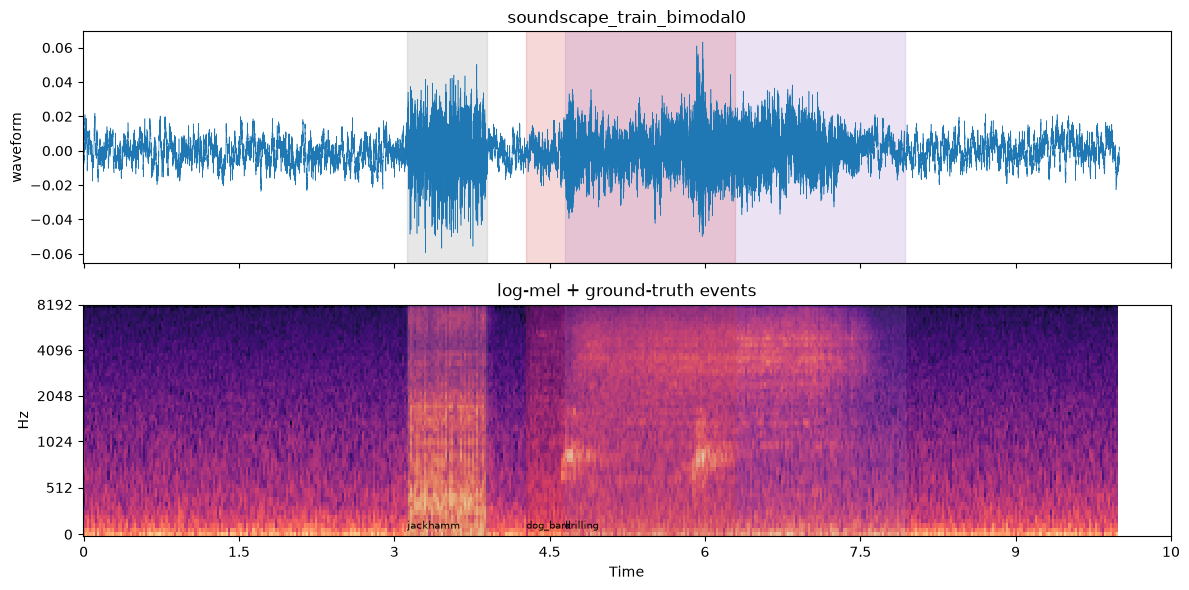

In [5]:
row = split_rows["train"][0]
y, mel = logmel(row["audio"])
t = np.arange(mel.shape[0]) * HOP_LENGTH / SAMPLE_RATE

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(np.arange(len(y)) / SAMPLE_RATE, y, linewidth=0.4)
axes[0].set_ylabel("waveform"); axes[0].set_title(row["name"])
librosa.display.specshow(mel.T, sr=SAMPLE_RATE, hop_length=HOP_LENGTH,
                         x_axis="time", y_axis="mel", ax=axes[1], cmap="magma")
for cid, start, end in row["events"]:
    for ax in axes:
        ax.axvspan(start, end, alpha=0.18, color=plt.cm.tab10(cid % 10))
    axes[1].text(start, N_MELS - 2, CLASSES[cid][:8], fontsize=7)
axes[1].set_title("log-mel + ground-truth events")
plt.tight_layout(); plt.show()

## Class co-occurrence

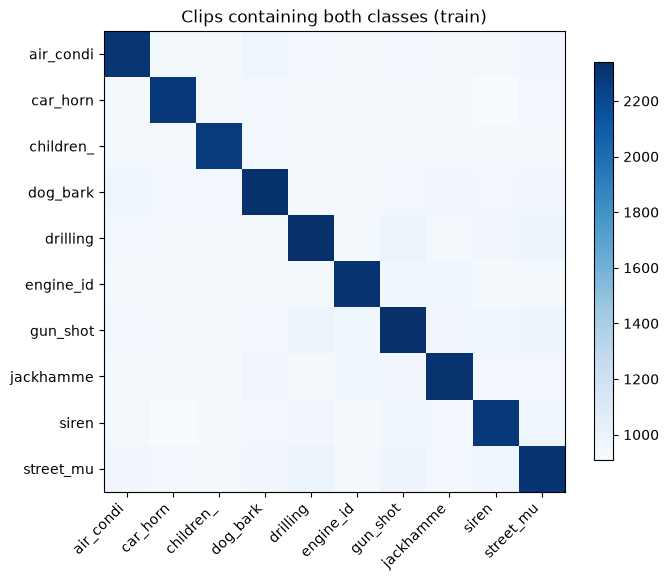

In [6]:
co = np.zeros((len(CLASSES), len(CLASSES)))
for row in split_rows["train"]:
    present = sorted({cid for cid, _, _ in row["events"]})
    for i in present:
        for j in present:
            co[i, j] += 1
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(co, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels([c[:9] for c in CLASSES], rotation=45, ha="right")
ax.set_yticklabels([c[:9] for c in CLASSES])
ax.set_title("Clips containing both classes (train)")
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

## Sanity checks and processed targets

In [7]:
problems = []
for split, rows in split_rows.items():
    for row in rows:
        for cid, start, end in row["events"]:
            if start < 0 or end > 10.0 + 1e-6 or end <= start:
                problems.append((split, row["name"], cid, start, end))
print("annotation problems:", len(problems))

names = {s: {r["name"] for r in split_rows[s]} for s in SPLITS}
print("train/val name overlap:", len(names["train"] & names["validate"]))
print("train/test name overlap:", len(names["train"] & names["test"]))

if (PROCESSED / "meta.json").exists():
    meta = json.loads((PROCESSED / "meta.json").read_text())
    print({k: meta[k] for k in ("num_classes", "num_frames", "frame_rate",
                                 "mel_mean", "mel_std")})
    for split in SPLITS:
        mel = np.load(PROCESSED / f"{split}_mel.npy", mmap_mode="r")
        with np.load(PROCESSED / f"{split}_targets.npz") as f:
            print(f"{split:>8s} mel {mel.shape} {mel.dtype}  "
                  f"presence {f['pres'].mean():.4f}  onsets {int(f['on'].sum())}  "
                  f"offsets {int(f['off'].sum())}")
else:
    print("processed data missing")

annotation problems: 0
train/val name overlap: 0
train/test name overlap: 0
{'num_classes': 10, 'num_frames': 500, 'frame_rate': 50.0, 'mel_mean': -18.015541076660156, 'mel_std': 13.418876647949219}
   train mel (6000, 500, 64) float16  presence 0.0939  onsets 26448  offsets 26448
validate mel (2000, 500, 64) float16  presence 0.0925  onsets 8776  offsets 8776
    test mel (2000, 500, 64) float16  presence 0.0930  onsets 8800  offsets 8800


## Takeaways

- Fill in after running: rare classes, boundary resolution, class imbalance and
  any annotation issues that would affect PSDS1/PSDS2.